# SC4002 Group 40 - Stage 1

## 1) Setup - Install dependencies and import libraries

In [1]:
import importlib.util
import subprocess
import sys

required_packages = {'torch': 'torch', 'numpy': 'numpy', 'tqdm': 'tqdm', 'matplotlib': 'matplotlib'}
missing_packages = [package for module, package in required_packages.items()
                    if importlib.util.find_spec(module) is None]
if missing_packages:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', *missing_packages])

In [2]:
import copy
import hashlib
import json
import math
import platform
import random
import re
import tarfile
import time
import urllib.request
import zipfile
from collections import Counter
from dataclasses import dataclass
from itertools import zip_longest
from pathlib import Path
from typing import Dict, Iterable, List, Optional, Sequence, Tuple

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.optim import Adam, AdamW
from torch.utils.data import DataLoader, Dataset
from tqdm import tqdm
import matplotlib
import matplotlib.pyplot as plt

print('Python:', platform.python_version())
print('PyTorch:', torch.__version__, '| NumPy:', np.__version__, '| Matplotlib:', matplotlib.__version__)
print('CUDA runtime:', torch.version.cuda, '| CUDA available:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))

Python: 3.12.6
PyTorch: 2.14.1+cpu | NumPy: 2.5.4 | Matplotlib: 3.11.2
CUDA runtime: None | CUDA available: False


### Inline configuration - Selected grid-search settings

The hyperparameters below were selected by the completed, separate grid search using
development combined score. This notebook runs only the selected configuration, not
the full search. Section 7 explains the selection procedure. The report appendix contains
the grid search details.

In [3]:
CONFIG = json.loads(r'''
{
  "seed": 42,
  "data_path": "1.0/data/en-US.jsonl",
  "experiment_dir": "experiments/notebook_stage1",
  "embedding": {
    "glove_path": "embeddings/glove.6B.300d.txt",
    "embedding_dim": 300,
    "freeze": true
  },
  "training": {
    "batch_size": 32,
    "num_epochs": 50,
    "learning_rate": 0.001,
    "optimizer": "adamw",
    "weight_decay": 0.0001,
    "slot_loss_weight": 1.0,
    "dropout": 0.5,
    "max_grad_norm": 1.0,
    "early_stopping_patience": 8
  },
  "model": {
    "hidden_dim": 256,
    "num_layers": 2
  }
}
''')
print(json.dumps(CONFIG, indent=2))

{
  "seed": 42,
  "data_path": "1.0/data/en-US.jsonl",
  "experiment_dir": "experiments/notebook_stage1",
  "embedding": {
    "glove_path": "embeddings/glove.6B.300d.txt",
    "embedding_dim": 300,
    "freeze": true
  },
  "training": {
    "batch_size": 32,
    "num_epochs": 50,
    "learning_rate": 0.001,
    "optimizer": "adamw",
    "weight_decay": 0.0001,
    "slot_loss_weight": 1.0,
    "dropout": 0.5,
    "max_grad_norm": 1.0,
    "early_stopping_patience": 8
  },
  "model": {
    "hidden_dim": 256,
    "num_layers": 2
  }
}


## 2) Data preparation - Download and verify the official splits

This section downloads the MASSIVE 1.0 English (en-US) dataset and Stanford GloVe 6B 300-dimensional word vectors for word embedding initialization. The original dataset splits are preserved using the partition field. Their sizes are printed and verified: 11,514 training, 2,033 validation, and 2,974 test examples.

In [4]:
def download_if_missing(url, destination):
    destination = Path(destination)
    if destination.is_file():
        print('Reusing archive:', destination)
        return destination
    destination.parent.mkdir(parents=True, exist_ok=True)
    partial = destination.with_suffix(destination.suffix + '.partial')
    print('Downloading:', url)
    last_report = [-1.0]
    started = time.monotonic()
    def progress(blocks, block_size, total):
        now = time.monotonic()
        if now - last_report[0] >= 5 or (total > 0 and blocks * block_size >= total):
            received = blocks * block_size
            if total > 0:
                received = min(received, total)
                print(f'  {100 * received / total:.1f}% | {received / 2**20:.1f}/{total / 2**20:.1f} MiB', flush=True)
            else:
                print(f'  {received / 2**20:.1f} MiB downloaded', flush=True)
            last_report[0] = now
    urllib.request.urlretrieve(url, partial, reporthook=progress)
    print(f'Download finished in {time.monotonic() - started:.1f}s', flush=True)
    partial.replace(destination)
    return destination

data_file = Path(CONFIG['data_path'])
if not data_file.is_file():
    archive = download_if_missing(
        'https://amazon-massive-nlu-dataset.s3.amazonaws.com/amazon-massive-dataset-1.0.tar.gz',
        'downloads/amazon-massive-dataset-1.0.tar.gz')
    print('Extracting English dataset...', flush=True)
    with tarfile.open(archive, 'r:gz') as bundle:
        candidates = [m for m in bundle.getmembers()
                      if m.isfile() and m.name.lstrip('./') == '1.0/data/en-US.jsonl']
        if len(candidates) != 1:
            raise ValueError('Expected exactly one MASSIVE 1.0 English dataset member.')
        data_file.parent.mkdir(parents=True, exist_ok=True)
        with bundle.extractfile(candidates[0]) as source, data_file.open('wb') as target:
            import shutil
            shutil.copyfileobj(source, target)

if not CONFIG['embedding'].get('glove_path'):
    raise ValueError('Set glove_path to use the intended pretrained GloVe baseline.')
glove_file = Path(CONFIG['embedding']['glove_path'])
if not glove_file.is_file():
    archive = download_if_missing('https://huggingface.co/stanfordnlp/glove/resolve/main/glove.6B.zip', 'downloads/glove.6B.zip')
    print('Extracting 300d GloVe vectors...', flush=True)
    with zipfile.ZipFile(archive) as bundle:
        glove_file.parent.mkdir(parents=True, exist_ok=True)
        with bundle.open('glove.6B.300d.txt') as source, glove_file.open('wb') as target:
            import shutil
            shutil.copyfileobj(source, target)
print('Dataset:', data_file, '| GloVe:', glove_file)

with data_file.open(encoding='utf-8') as stream:
    records = [json.loads(line) for line in stream if line.strip()]
split_counts = Counter(str(record['partition']).lower() for record in records)
expected_counts = {'train': 11514, 'dev': 2033, 'test': 2974}
print('Official split counts:', dict(split_counts))
assert dict(split_counts) == expected_counts, (split_counts, expected_counts)
assert len(records) == 16521

Dataset: 1.0\data\en-US.jsonl | GloVe: embeddings\glove.6B.300d.txt
Official split counts: {'test': 2974, 'train': 11514, 'dev': 2033}


## 3) Utilities - Reproducibility and experiment tracking

This section defines helper functions for setting random seeds, verifying dataset split sizes, and reporting parameter counts. It also implements an experiment tracker to record epoch-level training and validation metrics, save training logs, and store the best model checkpoint.

In [5]:
import json
import random
import time
from pathlib import Path
from typing import Dict, Iterable, List

import numpy as np
import torch


OFFICIAL_SPLITS = {
    "train": 11514,
    "dev": 2033,
    "test": 2974,
}


def set_seed(seed: int = 42) -> None:
    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def parameter_breakdown(model):
    counts = model.get_parameter_counts()
    embeddings = sum(parameter.numel() for parameter in model.embedding.parameters())
    return {'word_embeddings': embeddings,
            'stage1_model_excluding_embeddings': counts['total'] - embeddings,
            **counts}

def print_parameter_breakdown(model):
    counts = parameter_breakdown(model)
    print(f"Word embedding parameters: {counts['word_embeddings']:,}")
    print(f"Stage 1 model parameters (excluding embeddings): {counts['stage1_model_excluding_embeddings']:,}")
    print(f"Total pipeline parameters: {counts['total']:,} / 20,000,000")
    print(f"Trainable: {counts['trainable']:,} | Frozen: {counts['frozen']:,}")
    assert counts['word_embeddings'] + counts['stage1_model_excluding_embeddings'] == counts['total']
    assert counts['total'] <= 20_000_000


def seed_worker(worker_id: int) -> None:
    worker_seed = torch.initial_seed() % (2 ** 32)
    np.random.seed(worker_seed)
    random.seed(worker_seed)


def assert_official_split_counts(records: Iterable[Dict]) -> None:
    counts = {"train": 0, "dev": 0, "test": 0}

    for record in records:
        partition = str(record.get("partition", "")).lower()
        if partition in counts:
            counts[partition] += 1

    if counts != OFFICIAL_SPLITS:
        raise AssertionError(
            f"Split mismatch. Expected {OFFICIAL_SPLITS}, got {counts}."
        )


class ExperimentTracker:
    def __init__(self, experiment_dir: str) -> None:
        self.experiment_dir = Path(experiment_dir)
        self.experiment_dir.mkdir(parents=True, exist_ok=True)

        self.metrics_path = self.experiment_dir / "metrics_history.json"
        self.log_path = self.experiment_dir / "train.log"
        self.best_checkpoint_path = self.experiment_dir / "best_checkpoint.pt"

        self.history: List[Dict] = []

    def log(self, message: str) -> None:
        timestamp = time.strftime("%Y-%m-%d %H:%M:%S")
        line = f"[{timestamp}] {message}"

        with self.log_path.open("a", encoding="utf-8") as f:
            f.write(line + "\n")

        print(line)

    def append_metrics(self, metrics: Dict) -> None:
        self.history.append(metrics)

        with self.metrics_path.open("w", encoding="utf-8") as f:
            json.dump(self.history, f, indent=2)

    def save_checkpoint(
        self,
        model: torch.nn.Module,
        optimizer: torch.optim.Optimizer,
        epoch: int,
        validation_score: float,
    ) -> None:
        torch.save(
            {
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "epoch": epoch,
                "validation_score": validation_score,
            },
            self.best_checkpoint_path,
        )

## 4) Implementation preprocessing

This section converts the raw dataset into model inputs and labels. It tokenizes utterances into words and punctuation, builds word and label vocabularies from the training split only, and converts slot annotations into BIO tags. Word lookup is case-insensitive, and words absent from the training vocabulary are mapped to UNK. Batches are right-padded, with sequence lengths and attention masks retained to distinguish real tokens from padding.

The word embedding layer is initialized using GloVe vectors where available. Unmatched training words use seeded random vectors, PAD uses a zero vector, and UNK uses the mean pretrained vector.

This section also verifies that tokens extracted from annotations match those obtained from the raw utterances. 

In [6]:
import json
import re
from dataclasses import dataclass
from pathlib import Path
from typing import Dict, List, Tuple

import numpy as np
import torch
from torch.utils.data import DataLoader, Dataset



# Unicode-friendly tokenization
_TOKEN_PATTERN = re.compile(r"\w+(?:'\w+)?|[^\w\s]")

_SLOT_PATTERN = re.compile(
    r"\[\s*([^\[\]:]+?)\s*:\s*([^\]]+?)\s*\]"
)


@dataclass
class Vocabulary:
    word2id: Dict[str, int]
    intent2id: Dict[str, int]
    slot2id: Dict[str, int]


class MassiveDataset(Dataset):
    def __init__(self, examples: List[Dict]):
        self.examples = examples

    def __len__(self) -> int:
        return len(self.examples)

    def __getitem__(self, idx: int) -> Dict:
        return self.examples[idx]


def tokenize_words(text: str) -> List[str]:
    return _TOKEN_PATTERN.findall(text)


def parse_annot_utt(annot_utt: str) -> Tuple[List[str], List[str]]:
    tokens: List[str] = []
    tags: List[str] = []

    cursor = 0

    for match in _SLOT_PATTERN.finditer(annot_utt):
        prefix = annot_utt[cursor:match.start()]

        for token in tokenize_words(prefix):
            tokens.append(token)
            tags.append("O")

        slot_type = match.group(1).strip()
        slot_value = match.group(2).strip()

        slot_tokens = tokenize_words(slot_value)

        for i, token in enumerate(slot_tokens):
            tokens.append(token)
            tags.append(
                f"B-{slot_type}" if i == 0 else f"I-{slot_type}"
            )

        cursor = match.end()

    suffix = annot_utt[cursor:]

    for token in tokenize_words(suffix):
        tokens.append(token)
        tags.append("O")

    return tokens, tags


def load_massive_jsonl(data_path: str) -> List[Dict]:
    records: List[Dict] = []

    with Path(data_path).open("r", encoding="utf-8") as f:
        for line in f:
            if line.strip():
                records.append(json.loads(line))

    return records


def build_label_vocabs(
    train_records: List[Dict],
    enforce_official_counts: bool = True,
) -> Tuple[Dict[str, int], Dict[str, int]]:

    intent_labels = sorted(
        {str(record["intent"]) for record in train_records}
    )

    slot_types = set()

    for record in train_records:
        _, tags = parse_annot_utt(str(record["annot_utt"]))

        for tag in tags:
            if tag.startswith("B-") or tag.startswith("I-"):
                slot_types.add(tag[2:])

    sorted_slot_types = sorted(slot_types)

    intent2id = {
        intent: idx
        for idx, intent in enumerate(intent_labels)
    }

    slot2id = {
        "<PAD>": 0,
        "O": 1,
    }

    index = 2

    for slot_type in sorted_slot_types:
        slot2id[f"B-{slot_type}"] = index
        index += 1

        slot2id[f"I-{slot_type}"] = index
        index += 1

    if enforce_official_counts:

        if len(intent2id) != 60:
            raise AssertionError(
                f"Expected 60 intents, got {len(intent2id)}"
            )

        if len(slot_types) != 55:
            raise AssertionError(
                f"Expected 55 slot types, got {len(slot_types)}"
            )

    return intent2id, slot2id


def build_word_vocab(train_records: List[Dict]) -> Dict[str, int]:

    vocab_words = set()

    for record in train_records:
        for token in tokenize_words(str(record["utt"])):
            vocab_words.add(token.lower())

    sorted_words = sorted(vocab_words)

    word2id = {
        "<PAD>": 0,
        "<UNK>": 1,
    }

    for idx, word in enumerate(sorted_words, start=2):
        word2id[word] = idx

    return word2id


def load_glove_embeddings(
    glove_path: str,
    word2id: Dict[str, int],
    embedding_dim: int,
) -> torch.Tensor:

    embeddings = np.random.normal(
        0.0,
        0.02,
        size=(len(word2id), embedding_dim),
    ).astype(np.float32)

    embeddings[word2id["<PAD>"]] = np.zeros(
        embedding_dim,
        dtype=np.float32,
    )

    if glove_path:

        all_vectors = []

        with Path(glove_path).open(
            "r",
            encoding="utf-8",
        ) as f:

            for line in f:
                parts = line.strip().split()

                if len(parts) != embedding_dim + 1:
                    continue

                word = parts[0]

                vector = np.asarray(
                    parts[1:],
                    dtype=np.float32,
                )

                all_vectors.append(vector)

                if word in word2id:
                    embeddings[word2id[word]] = vector

        if all_vectors:
            mean_vector = np.mean(
                all_vectors,
                axis=0,
            )
        else:
            mean_vector = np.zeros(
                embedding_dim,
                dtype=np.float32,
            )

        embeddings[word2id["<UNK>"]] = mean_vector

    return torch.tensor(
        embeddings,
        dtype=torch.float32,
    )


def _encode_example(
    record: Dict,
    vocab: Vocabulary,
) -> Dict:

    parsed_tokens, slot_tags = parse_annot_utt(
        str(record["annot_utt"])
    )

    tokens = (
        parsed_tokens
        if parsed_tokens
        else tokenize_words(str(record["utt"]))
    )

    input_ids = [
        vocab.word2id.get(
            token.lower(),
            vocab.word2id["<UNK>"],
        )
        for token in tokens
    ]

    slot_labels = [
        vocab.slot2id.get(
            tag,
            vocab.slot2id["O"],
        )
        for tag in slot_tags
    ]

    if len(slot_labels) != len(input_ids):
        raise ValueError(
            f"Token-label mismatch\n"
            f"utt={record['utt']}\n"
            f"annot_utt={record['annot_utt']}\n"
            f"tokens={len(input_ids)}\n"
            f"labels={len(slot_labels)}"
        )

    return {
        "input_ids": input_ids,
        "intent_label": vocab.intent2id[
            str(record["intent"])
        ],
        "slot_labels": slot_labels,
        "raw_utt": str(record["utt"]),
        "raw_annot_utt": str(record["annot_utt"]),
    }


def _collate_batch(batch: List[Dict]) -> Dict:

    input_ids = [
        torch.tensor(
            item["input_ids"],
            dtype=torch.long,
        )
        for item in batch
    ]

    slot_labels = [
        torch.tensor(
            item["slot_labels"],
            dtype=torch.long,
        )
        for item in batch
    ]

    padded_input_ids = torch.nn.utils.rnn.pad_sequence(
        input_ids,
        batch_first=True,
        padding_value=0,
    )

    padded_slot_labels = torch.nn.utils.rnn.pad_sequence(
        slot_labels,
        batch_first=True,
        padding_value=0,
    )

    attention_mask = (
        padded_input_ids != 0
    ).long()

    seq_lens = torch.tensor(
        [len(item["input_ids"]) for item in batch],
        dtype=torch.long,
    )

    intent_labels = torch.tensor(
        [item["intent_label"] for item in batch],
        dtype=torch.long,
    )

    raw_utt = [
        item["raw_utt"]
        for item in batch
    ]

    raw_annot_utt = [
        item["raw_annot_utt"]
        for item in batch
    ]

    return {
        "input_ids": padded_input_ids,
        "attention_mask": attention_mask,
        "seq_lens": seq_lens,
        "intent_label": intent_labels,
        "slot_labels": padded_slot_labels,
        "raw_utt": raw_utt,
        "raw_annot_utt": raw_annot_utt,
    }


def get_dataloaders(
    data_path: str,
    batch_size: int,
    glove_path: str = "",
    embedding_dim: int = 300,
    enforce_official_counts: bool = True,
):

    records = load_massive_jsonl(data_path)

    if enforce_official_counts:
        assert_official_split_counts(records)

    split_records = {
        "train": [],
        "dev": [],
        "test": [],
    }

    for record in records:
        partition = str(record.get("partition", "")).lower()

        if partition in split_records:
            split_records[partition].append(record)

    intent2id, slot2id = build_label_vocabs(
        split_records["train"],
        enforce_official_counts=
        enforce_official_counts,
    )

    word2id = build_word_vocab(
        split_records["train"]
    )

    vocab = Vocabulary(
        word2id=word2id,
        intent2id=intent2id,
        slot2id=slot2id,
    )

    loaders = {}

    for split_name, split_data in split_records.items():

        encoded = [
            _encode_example(record, vocab)
            for record in split_data
        ]

        dataset = MassiveDataset(encoded)

        loaders[split_name] = DataLoader(
            dataset,
            batch_size=batch_size,
            shuffle=(split_name == "train"),
            collate_fn=_collate_batch,
        )

    embedding_matrix = load_glove_embeddings(
        glove_path,
        word2id,
        embedding_dim,
    )

    return loaders, vocab, embedding_matrix

In [7]:
assert_official_split_counts(records)
for record in records:
    annotation_tokens, _ = parse_annot_utt(record['annot_utt'])
    assert annotation_tokens == tokenize_words(record['utt']), record.get('id')
print('All annotation-derived token sequences match raw utt tokenization.')
example = next(record for record in records if record['partition'] == 'train')
print('Training utt:', example['utt'])
print('Tokens and BIO labels:', parse_annot_utt(example['annot_utt']))

All annotation-derived token sequences match raw utt tokenization.
Training utt: wake me up at nine am on friday
Tokens and BIO labels: (['wake', 'me', 'up', 'at', 'nine', 'am', 'on', 'friday'], ['O', 'O', 'O', 'O', 'B-time', 'I-time', 'O', 'B-date'])


## 5) Evaluation - Shared scoring functions

This section defines the shared evaluation functions for intent accuracy and slot micro-F1. Intent accuracy measures the percentage of utterances with a correctly predicted intent:

`Intent accuracy = 100 * correct predictions / number of utterances`

Slot micro-F1 compares exact pairs of slot type and tokenized span text within each utterance, then pools true positives, false positives and false negatives across all utterances:

`Slot micro-F1 = 100 * 2TP / (2TP + FP + FN)`

The same scoring rules are used across all experiments.

In [8]:
from typing import Dict, Iterable, List, Sequence, Tuple
from itertools import zip_longest

import torch



def _tags_from_ids(label_ids: Sequence[int], id2slot: Dict[int, str]) -> List[str]:
    return [id2slot[int(idx)] for idx in label_ids]


def bio_tags_to_spans(tokens: Sequence[str], tags: Sequence[str]) -> List[Tuple[str, str]]:
    if len(tokens) != len(tags):
        raise ValueError('Token and BIO tag counts must match.')
    spans: List[Tuple[str, str]] = []
    current_type = None
    current_tokens: List[str] = []

    def flush() -> None:
        nonlocal current_type, current_tokens
        if current_type and current_tokens:
            spans.append((current_type, " ".join(current_tokens)))
        current_type = None
        current_tokens = []

    for token, tag in zip(tokens, tags):
        if tag == "O" or tag == "<PAD>":
            flush()
            continue

        if "-" not in tag:
            flush()
            continue

        prefix, slot_type = tag.split("-", 1)
        if prefix == "B":
            flush()
            current_type = slot_type
            current_tokens = [token]
        elif prefix == "I" and current_type == slot_type:
            current_tokens.append(token)
        else:
            flush()
            current_type = slot_type
            current_tokens = [token]

    flush()
    return spans


def compute_slot_micro_f1(
    all_gold_spans: Iterable[List[Tuple[str, str]]],
    all_pred_spans: Iterable[List[Tuple[str, str]]],
) -> float:
    tp = fp = fn = 0

    missing = object()
    for gold_spans, pred_spans in zip_longest(all_gold_spans, all_pred_spans, fillvalue=missing):
        if gold_spans is missing or pred_spans is missing:
            raise ValueError('Gold and predicted span collections must have equal lengths.')
        gold_set = set(gold_spans)
        pred_set = set(pred_spans)

        tp += len(gold_set & pred_set)
        fp += len(pred_set - gold_set)
        fn += len(gold_set - pred_set)

    denominator = (2 * tp + fp + fn)
    if denominator == 0:
        return 0.0

    return 100.0 * (2 * tp) / denominator


def compute_intent_accuracy(gold: List[int], pred: List[int]) -> float:
    if len(gold) != len(pred):
        raise ValueError('Gold and predicted intent counts must match.')
    if not gold:
        return 0.0
    correct = sum(1 for g, p in zip(gold, pred) if g == p)
    return 100.0 * correct / len(gold)


def evaluate_model(
    model: torch.nn.Module,
    dataloader,
    device: torch.device,
    id2slot: Dict[int, str],
    round_results: bool = True,
) -> Dict[str, float]:
    model.eval()

    all_gold_intents: List[int] = []
    all_pred_intents: List[int] = []
    all_gold_spans: List[List[Tuple[str, str]]] = []
    all_pred_spans: List[List[Tuple[str, str]]] = []

    with torch.no_grad():
        for batch in dataloader:
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            seq_lens = batch["seq_lens"].to(device)

            _, intent_logits, slot_logits = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                seq_lens=seq_lens,
            )

            pred_intents = intent_logits.argmax(dim=-1).cpu().tolist()
            gold_intents = batch["intent_label"].cpu().tolist()
            all_pred_intents.extend(pred_intents)
            all_gold_intents.extend(gold_intents)

            pred_slot_ids = model.decode_slots(slot_logits, attention_mask).cpu()
            gold_slot_ids = batch["slot_labels"].cpu()

            for i, seq_len in enumerate(batch["seq_lens"].tolist()):
                tokens = tokenize_words(batch["raw_utt"][i])
                if len(tokens) != seq_len:
                    raise ValueError('Raw utterance token count does not match encoded sequence length.')

                pred_tags = _tags_from_ids(pred_slot_ids[i, :seq_len].tolist(), id2slot)
                gold_tags = _tags_from_ids(gold_slot_ids[i, :seq_len].tolist(), id2slot)

                all_pred_spans.append(bio_tags_to_spans(tokens, pred_tags))
                all_gold_spans.append(bio_tags_to_spans(tokens, gold_tags))

    intent_accuracy = compute_intent_accuracy(all_gold_intents, all_pred_intents)
    slot_micro_f1 = compute_slot_micro_f1(all_gold_spans, all_pred_spans)

    results = {
        "intent_accuracy": intent_accuracy,
        "slot_micro_f1": slot_micro_f1,
        "combined_score": (intent_accuracy + slot_micro_f1) / 2.0,
    }
    return {key: round(value, 2) for key, value in results.items()} if round_results else results

## 6) Stage 1 Model

This section defines a joint model for intent classification and slot filling. The model takes token IDs, padding masks and sequence lengths as inputs. A GloVe-initialized embedding layer converts tokens into 300-dimensional vectors, which pass through a two-layer BiLSTM to capture context from both directions.

The shared BiLSTM output feeds two branches:

- Intent classification: attention pooling combines token features into a sentence representation. Dropout and a linear classifier predict one of 60 intents.

- Slot filling: dropout and a linear layer produce scores for 112 BIO tags per token. A CRF models relationships between neighbouring tags, while Viterbi decoding selects the highest-scoring sequence that follows the BIO constraints.
The model is trained jointly using:

`Total loss = intent cross-entropy + slot_loss_weight * CRF loss`

Training uses AdamW, gradient clipping and a learning-rate scheduler that reduces the learning rate when development performance stops improving.

For each utterance, the system returns one intent label and a set of slot-type/span pairs.

In [ ]:
import math
from typing import Dict, Optional, Tuple

import torch
import torch.nn as nn
import torch.nn.functional as F


def _log_sum_exp(tensor: torch.Tensor, dim: int) -> torch.Tensor:
    """
    Numerically stable log-sum-exp along a specified dimension.
    Prevents floating point overflow by subtracting the maximum value.
    """
    reachable = torch.isfinite(tensor).any(dim=dim, keepdim=True)
    safe = torch.where(reachable, tensor, torch.zeros_like(tensor))
    result = torch.logsumexp(safe, dim=dim)
    return result.masked_fill(~reachable.squeeze(dim), float('-inf'))


class LinearChainCRF(nn.Module):
    """
    Linear-chain Conditional Random Field (CRF) for slot sequence tagging.

    Learns transition preferences, with hard BIO constraints when id2slot
    is supplied. Omitting the mapping supports legacy unconstrained models.
    """

    def __init__(self, num_tags: int, id2slot: Optional[Dict[int, str]] = None) -> None:
        super().__init__()
        self.num_tags = num_tags
        allowed = torch.ones(num_tags, num_tags, dtype=torch.bool)
        start = torch.ones(num_tags, dtype=torch.bool)
        end = torch.ones(num_tags, dtype=torch.bool)
        if id2slot is not None:
            if set(id2slot) != set(range(num_tags)) or id2slot.get(0) != '<PAD>':
                raise ValueError('id2slot must cover every tag ID with <PAD> at ID 0.')
            labels = [id2slot[i] for i in range(num_tags)]
            if len(set(labels)) != num_tags or 'O' not in labels:
                raise ValueError('Slot labels must be unique and include O.')
            for tag in labels[1:]:
                if tag != 'O' and (not tag.startswith(('B-', 'I-')) or not tag[2:]):
                    raise ValueError(f'Invalid BIO label: {tag}')
                if tag.startswith('I-') and 'B-' + tag[2:] not in labels:
                    raise ValueError(f'Missing B tag for {tag}')
            start[0] = end[0] = False
            allowed[0, :] = False
            allowed[:, 0] = False
            for j, tag in enumerate(labels):
                if tag.startswith('I-'):
                    start[j] = False
                    for i, previous in enumerate(labels):
                        allowed[i, j] = previous in ('B-' + tag[2:], tag)
        # Derived from the vocabulary; do not change checkpoint tensor keys.
        self.register_buffer('allowed_transitions', allowed, persistent=False)
        self.register_buffer('allowed_start', start, persistent=False)
        self.register_buffer('allowed_end', end, persistent=False)

        # Transition score from tag i to tag j
        self.transitions = nn.Parameter(torch.empty(num_tags, num_tags))
        self.start_transitions = nn.Parameter(torch.empty(num_tags))
        self.end_transitions = nn.Parameter(torch.empty(num_tags))
        self.reset_parameters()

    def _constrained_scores(self):
        return (self.transitions.masked_fill(~self.allowed_transitions, float('-inf')),
                self.start_transitions.masked_fill(~self.allowed_start, float('-inf')),
                self.end_transitions.masked_fill(~self.allowed_end, float('-inf')))

    def _validate(self, emissions, mask, tags=None):
        if emissions.ndim != 3 or emissions.shape[-1] != self.num_tags or emissions.shape[1] == 0:
            raise ValueError('Expected nonempty emissions [batch, length, num_tags].')
        if mask.shape != emissions.shape[:2] or not ((mask == 0) | (mask == 1)).all():
            raise ValueError('Mask must match emissions and contain only 0/1.')
        mask = mask.bool()
        if not mask[:, 0].all() or (mask[:, 1:] & ~mask[:, :-1]).any():
            raise ValueError('Each sequence must be nonempty and right-padded.')
        if tags is not None:
            if tags.shape != mask.shape or ((tags < 0) | (tags >= self.num_tags)).any():
                raise ValueError('Gold tags must match mask shape and be valid IDs.')
            if not self.allowed_start[tags[:, 0]].all():
                raise ValueError('Gold sequence has an invalid BIO start.')
            valid = self.allowed_transitions[tags[:, :-1], tags[:, 1:]]
            if (~valid & mask[:, 1:]).any():
                raise ValueError('Gold sequence has an invalid BIO transition or PAD tag.')
            last = tags.gather(1, (mask.sum(1) - 1).unsqueeze(1)).squeeze(1)
            if not self.allowed_end[last].all():
                raise ValueError('Gold sequence ends with an invalid tag.')
        return mask

    def reset_parameters(self) -> None:
        """Initialize transition parameters uniformly."""
        nn.init.uniform_(self.transitions, -0.1, 0.1)
        nn.init.uniform_(self.start_transitions, -0.1, 0.1)
        nn.init.uniform_(self.end_transitions, -0.1, 0.1)

    def forward(
        self, emissions: torch.Tensor, tags: torch.Tensor, mask: torch.Tensor
    ) -> torch.Tensor:
        """
        Compute negative log-likelihood loss for a batch of sequences.

        Args:
            emissions: Emission scores of shape [batch_size, seq_len, num_tags].
            tags: Target tag indices of shape [batch_size, seq_len].
            mask: Binary tensor of shape [batch_size, seq_len] (1 for valid tokens, 0 for pad).

        Returns:
            Scalar tensor representing mean negative log-likelihood.
        """
        mask = self._validate(emissions, mask, tags)
        gold_score = self._score_sentence(emissions, tags, mask)
        forward_score = self._compute_partition(emissions, mask)
        return (forward_score - gold_score).mean()

    def _score_sentence(
        self, emissions: torch.Tensor, tags: torch.Tensor, mask: torch.Tensor
    ) -> torch.Tensor:
        """Compute the unnormalized path score for the gold tag sequence."""
        batch_size, seq_len, _ = emissions.shape
        transitions, start, end = self._constrained_scores()
        score = torch.zeros(batch_size, device=emissions.device)

        # Transition from start state to first token tag
        first_tags = tags[:, 0]
        score = score + start[first_tags]

        for t in range(seq_len):
            m_t = mask[:, t].bool()
            curr_tags = tags[:, t]

            # Token emission score
            emit_score = emissions[torch.arange(batch_size), t, curr_tags]
            score = score + torch.where(m_t, emit_score, 0.0)

            # Tag transition score
            if t > 0:
                prev_tags = tags[:, t - 1]
                trans_score = transitions[prev_tags, curr_tags]
                score = score + torch.where(m_t, trans_score, 0.0)

        # Transition from the last valid token to the end state
        seq_lens = mask.long().sum(dim=1)
        last_indices = torch.clamp(seq_lens - 1, min=0)
        last_tags = tags[torch.arange(batch_size), last_indices]
        score = score + end[last_tags]

        return score

    def _compute_partition(
        self, emissions: torch.Tensor, mask: torch.Tensor
    ) -> torch.Tensor:
        """Compute log-sum-exp over all valid paths using the forward algorithm."""
        batch_size, seq_len, _ = emissions.shape
        transitions, start, end = self._constrained_scores()
        alpha = start.unsqueeze(0) + emissions[:, 0]

        for t in range(1, seq_len):
            m_t = mask[:, t].unsqueeze(1).bool()
            # Broadcast alpha [B, K, 1] + transitions [1, K, K] -> [B, K, K]
            scores = alpha.unsqueeze(2) + transitions.unsqueeze(0)
            next_alpha = _log_sum_exp(scores, dim=1) + emissions[:, t]
            # Only update state if position is not padding
            alpha = torch.where(m_t, next_alpha, alpha)

        alpha = alpha + end.unsqueeze(0)
        return _log_sum_exp(alpha, dim=1)

    def decode(self, emissions: torch.Tensor, mask: torch.Tensor) -> torch.Tensor:
        """
        Find the highest-scoring tag sequence using Viterbi decoding.

        Args:
            emissions: Emission scores of shape [batch_size, seq_len, num_tags].
            mask: Binary tensor of shape [batch_size, seq_len].

        Returns:
            Decoded tag indices of shape [batch_size, seq_len].
        """
        mask = self._validate(emissions, mask)
        batch_size, seq_len, _ = emissions.shape
        transitions, start, end = self._constrained_scores()
        viterbi = start.unsqueeze(0) + emissions[:, 0]
        backpointers = []

        for t in range(1, seq_len):
            m_t = mask[:, t].unsqueeze(1).bool()
            scores = viterbi.unsqueeze(2) + transitions.unsqueeze(0)
            max_scores, best_tags = scores.max(dim=1)
            next_viterbi = max_scores + emissions[:, t]
            viterbi = torch.where(m_t, next_viterbi, viterbi)
            backpointers.append(best_tags)

        viterbi = viterbi + end.unsqueeze(0)
        best_last_tags = viterbi.argmax(dim=1).tolist()
        seq_lens = mask.long().sum(dim=1).tolist()

        best_paths = []
        for b in range(batch_size):
            length = seq_lens[b]
            if length <= 0:
                best_paths.append([0] * seq_len)
                continue

            best_tag = best_last_tags[b]
            path = [best_tag]
            for t in range(length - 2, -1, -1):
                best_tag = backpointers[t][b, best_tag].item()
                path.append(best_tag)
            path.reverse()
            path = path + [0] * (seq_len - length)
            best_paths.append(path)

        return torch.tensor(best_paths, dtype=torch.long, device=emissions.device)


class JointBiLSTMAttention(nn.Module):
    """
    Joint BiLSTM model for simultaneous intent classification and slot filling.

    The architecture shares a bidirectional LSTM encoder across two heads:
      1. Intent head: pools contextual token embeddings using learned linear
         attention scores into an utterance vector, then classifies the intent.
      2. Slot head: projects hidden states to tag emissions and uses a linear-chain
         CRF to decode the highest-scoring tag sequence.
    """

    def __init__(
        self,
        vocab_size: int,
        embedding_dim: int,
        hidden_dim: int,
        num_intents: int,
        num_slots: int,
        num_layers: int = 2,
        dropout: float = 0.3,
        slot_loss_weight: float = 1.0,
        embedding_matrix: Optional[torch.Tensor] = None,
        freeze_embeddings: bool = False,
        use_crf: bool = True,
        id2slot: Optional[Dict[int, str]] = None,
        enforce_bio: bool = True,
    ) -> None:
        super().__init__()
        if not math.isfinite(slot_loss_weight) or slot_loss_weight < 0:
            raise ValueError('slot_loss_weight must be finite and nonnegative.')
        self.slot_loss_weight = slot_loss_weight
        self.hidden_dim = hidden_dim
        self.num_layers = num_layers
        self.use_crf = use_crf

        # Word embedding layer
        if embedding_matrix is not None:
            if tuple(embedding_matrix.shape) != (vocab_size, embedding_dim):
                raise ValueError('Embedding matrix must have shape [vocab_size, embedding_dim].')
            self.embedding = nn.Embedding.from_pretrained(
                embedding_matrix, freeze=freeze_embeddings, padding_idx=0
            )
        else:
            self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)
            self.embedding.weight.requires_grad_(not freeze_embeddings)

        # Shared bidirectional LSTM encoder
        self.encoder = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            dropout=dropout if num_layers > 1 else 0.0,
            bidirectional=True,
            batch_first=True,
        )

        projection_dim = hidden_dim * 2

        # Intent classification branch
        self.attn_score = nn.Linear(projection_dim, 1)
        self.intent_dropout = nn.Dropout(dropout)
        self.intent_head = nn.Linear(projection_dim, num_intents)

        # Slot filling branch
        self.slot_dropout = nn.Dropout(dropout)
        self.slot_head = nn.Linear(projection_dim, num_slots)

        # Linear-chain CRF for slot transitions
        if use_crf and enforce_bio and id2slot is None:
            raise ValueError('Constrained CRF requires id2slot; use enforce_bio=False only for legacy runs.')
        self.crf = LinearChainCRF(num_slots, id2slot if enforce_bio else None) if use_crf else None

        self._check_parameter_budget()

    def get_parameter_counts(self) -> Dict[str, int]:
        """Return total, trainable, and frozen parameter counts."""
        total = sum(p.numel() for p in self.parameters())
        trainable = sum(p.numel() for p in self.parameters() if p.requires_grad)
        frozen = total - trainable
        return {"total": total, "trainable": trainable, "frozen": frozen}

    def _check_parameter_budget(self) -> None:
        """Verify model parameter count stays within course limits (<= 20M)."""
        counts = self.get_parameter_counts()
        total_params = counts["total"]
        if total_params > 20_000_000:
            raise AssertionError(
                f"Model exceeds 20M parameter ceiling: {total_params:,} parameters."
            )

    def _attention_pool(
        self, encoded: torch.Tensor, attention_mask: Optional[torch.Tensor]
    ) -> torch.Tensor:
        """Softmax-normalize learned token scores and pool token states."""
        scores = self.attn_score(encoded).squeeze(-1)
        if attention_mask is not None:
            scores = scores.masked_fill(attention_mask == 0, float("-inf"))

        attn_weights = F.softmax(scores, dim=1)
        return torch.bmm(attn_weights.unsqueeze(1), encoded).squeeze(1)

    @torch.no_grad()
    def decode_slots(
        self, slot_logits: torch.Tensor, attention_mask: torch.Tensor
    ) -> torch.Tensor:
        """Return tag IDs [batch, length] from emissions, with padding ID 0.

        Uses Viterbi when a CRF is enabled, otherwise token-wise argmax.
        Call eval() before forward() for deterministic inference without dropout.
        """
        if self.crf is not None:
            return self.crf.decode(slot_logits, attention_mask)
        return slot_logits.argmax(dim=-1).masked_fill(attention_mask == 0, 0)

    def forward(
        self,
        input_ids: torch.Tensor,
        attention_mask: Optional[torch.Tensor] = None,
        seq_lens: Optional[torch.Tensor] = None,
        intent_labels: Optional[torch.Tensor] = None,
        slot_labels: Optional[torch.Tensor] = None,
    ) -> Tuple[Optional[torch.Tensor], torch.Tensor, torch.Tensor]:
        """
        Run forward pass for intent classification and slot labeling.

        Args:
            input_ids: Token IDs of shape [batch_size, max_seq_len].
            attention_mask: Mask of shape [batch_size, max_seq_len] (1 for tokens, 0 for pad).
            seq_lens: Sequence lengths before padding of shape [batch_size].
            intent_labels: Ground-truth intent labels of shape [batch_size].
            slot_labels: Ground-truth slot labels of shape [batch_size, max_seq_len].

        Returns:
            Tuple of (loss, intent_logits, slot_logits):
              - loss: Multi-task loss scalar if any labels are provided, else None.
              - intent_logits: Shape [batch_size, num_intents].
              - slot_logits: Genuine emission scores, shape
                [batch_size, max_seq_len, num_slots], with or without labels.
                Use decode_slots(slot_logits, attention_mask) for predicted tags.
        """
        if input_ids.ndim != 2 or input_ids.shape[0] == 0 or input_ids.shape[1] == 0:
            raise ValueError('input_ids must be a nonempty [batch, length] tensor.')
        token_mask = input_ids != 0
        if attention_mask is None:
            attention_mask = token_mask
        elif (attention_mask.shape != input_ids.shape
              or not ((attention_mask == 0) | (attention_mask == 1)).all()
              or not torch.equal(attention_mask.bool(), token_mask)):
            raise ValueError('attention_mask must mark precisely the non-PAD input tokens.')
        attention_mask = attention_mask.bool()
        if not attention_mask[:, 0].all() or (attention_mask[:, 1:] & ~attention_mask[:, :-1]).any():
            raise ValueError('Inputs must contain nonempty, right-padded sequences.')
        inferred_lengths = attention_mask.long().sum(1)
        if seq_lens is not None and not torch.equal(seq_lens.to(inferred_lengths.device), inferred_lengths):
            raise ValueError('seq_lens must equal the number of real tokens in each sequence.')
        seq_lens = inferred_lengths
        embeddings = self.embedding(input_ids)

        # Efficient sequence packing to ignore padding steps
        if seq_lens is not None:
            packed = nn.utils.rnn.pack_padded_sequence(
                embeddings, seq_lens.cpu(), batch_first=True, enforce_sorted=False
            )
            packed_out, _ = self.encoder(packed)
            encoded, _ = nn.utils.rnn.pad_packed_sequence(
                packed_out, batch_first=True, total_length=input_ids.shape[1]
            )
        else:
            encoded, _ = self.encoder(embeddings)

        # 1. Intent predictions
        pooled = self._attention_pool(encoded, attention_mask)
        intent_logits = self.intent_head(self.intent_dropout(pooled))

        # 2. Slot emission logits
        slot_logits = self.slot_head(self.slot_dropout(encoded))

        # 3. Multi-task loss
        loss = None
        if intent_labels is not None or slot_labels is not None:
            total_loss = torch.tensor(0.0, device=input_ids.device)

            if intent_labels is not None:
                total_loss = total_loss + F.cross_entropy(intent_logits, intent_labels)

            if slot_labels is not None:
                if self.crf is not None:
                    mask = (
                        attention_mask
                        if attention_mask is not None
                        else (input_ids != 0).long()
                    )
                    slot_loss = self.crf(slot_logits, slot_labels, mask)
                else:
                    slot_loss = F.cross_entropy(
                        slot_logits.view(-1, slot_logits.shape[-1]),
                        slot_labels.view(-1),
                        ignore_index=0,
                    )
                total_loss = total_loss + self.slot_loss_weight * slot_loss

            loss = total_loss

        return loss, intent_logits, slot_logits

In [10]:
training_records = [record for record in records if record['partition'] == 'train']
preview_words = build_word_vocab(training_records)
preview_intents, preview_slots = build_label_vocabs(training_records, enforce_official_counts=True)
preview_model = JointBiLSTMAttention(
    vocab_size=len(preview_words), embedding_dim=CONFIG['embedding']['embedding_dim'],
    hidden_dim=CONFIG['model']['hidden_dim'], num_intents=len(preview_intents),
    num_slots=len(preview_slots), id2slot={i: name for name, i in preview_slots.items()},
    num_layers=CONFIG['model']['num_layers'], dropout=CONFIG['training']['dropout'],
    slot_loss_weight=CONFIG['training']['slot_loss_weight'],
    freeze_embeddings=CONFIG['embedding']['freeze'])
print_parameter_breakdown(preview_model)
assert preview_model.get_parameter_counts()['total'] <= 20_000_000
print('Intent classes:', len(preview_intents), '| BIO tags:', len(preview_slots))
del preview_model

Word embedding parameters: 1,588,200
Stage 1 model parameters (excluding embeddings): 2,821,261
Total pipeline parameters: 4,409,461 / 20,000,000
Trainable: 2,821,261 | Frozen: 1,588,200
Intent classes: 60 | BIO tags: 112


## 7) Grid-search hyperparameter tuning

A separate grid search evaluated 64 combinations of hidden size, dropout, weight decay, learning rate, slot-loss weight and embedding freezing.

Each trial used seed 42 and trained for up to 50 epochs, with early stopping after eight consecutive epochs without improvement in the development combined score:

`Combined score = (intent accuracy + slot micro-F1) / 2`

The best configuration was selected using development results only. Test results were not used for tuning.

This notebook skips the full search and uses the selected configuration defined in Section 1. Detailed search results are provided in the report appendix.

The completed search was run separately. Its selected configuration has been copied into Section 1 so earlier data preparation and model-count cells can use the same settings. Do not redefine CONFIG here: the notebook uses one fixed configuration throughout.

## 8) Stage 1 Training

This section trains the model using the training split and selected hyperparameters. Training and validation losses, development metrics and elapsed time are recorded for each epoch.

The checkpoint with the highest development combined score is saved:

`Combined score = (intent accuracy + slot micro-F1) / 2`

Early stopping ends training after the configured number of consecutive epochs without improvement.

In [11]:
import argparse
import json
from pathlib import Path

import torch
from torch.optim import Adam, AdamW
from torch.utils.data import DataLoader
from tqdm import tqdm



def load_config(config_path: str):
    with Path(config_path).open("r", encoding="utf-8") as f:
        return json.load(f)


def make_optimizer(model, config):
    optimizer_name = config["training"]["optimizer"].lower()
    lr = config["training"]["learning_rate"]
    weight_decay = config["training"].get("weight_decay", 0.0)

    if optimizer_name == "adamw":
        return AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    return Adam(model.parameters(), lr=lr, weight_decay=weight_decay)


def evaluate_loss(model, dataloader, device):
    model.eval()
    total_loss = 0.0
    count = 0

    with torch.no_grad():
        for batch in dataloader:
            loss, _, _ = model(
                input_ids=batch["input_ids"].to(device),
                attention_mask=batch["attention_mask"].to(device),
                seq_lens=batch["seq_lens"].to(device),
                intent_labels=batch["intent_label"].to(device),
                slot_labels=batch["slot_labels"].to(device),
            )
            size = len(batch['seq_lens'])
            total_loss += float(loss.item()) * size
            count += size

    return total_loss / max(1, count)


def train_stage1(config):
    config = copy.deepcopy(config)
    set_seed(int(config.get("seed", 42)))

    trackers = ExperimentTracker(config["experiment_dir"])
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    dataloaders, vocab, embedding_matrix = get_dataloaders(
        data_path=config["data_path"],
        batch_size=int(config["training"]["batch_size"]),
        glove_path=config["embedding"].get("glove_path", ""),
        embedding_dim=int(config["embedding"]["embedding_dim"]),
        enforce_official_counts=True,
    )

    # Match the grid worker's independent, seeded shuffle and initialization.
    generator = torch.Generator().manual_seed(int(config.get('seed', 42)))
    dataloaders['train'] = DataLoader(
        dataloaders['train'].dataset, batch_size=int(config['training']['batch_size']),
        shuffle=True, collate_fn=_collate_batch, generator=generator)
    set_seed(int(config.get('seed', 42)))

    model = JointBiLSTMAttention(
        vocab_size=len(vocab.word2id),
        embedding_dim=int(config["embedding"]["embedding_dim"]),
        hidden_dim=int(config["model"]["hidden_dim"]),
        num_intents=len(vocab.intent2id),
        num_slots=len(vocab.slot2id),
        id2slot={idx: slot for slot, idx in vocab.slot2id.items()},
        num_layers=int(config["model"].get("num_layers", 2)),
        dropout=float(config["training"].get("dropout", 0.3)),
        slot_loss_weight=float(config["training"].get("slot_loss_weight", 1.0)),
        embedding_matrix=embedding_matrix,
        freeze_embeddings=bool(config["embedding"].get("freeze", False)),
    ).to(device)

    print_parameter_breakdown(model)
    assert model.get_parameter_counts()['total'] <= 20_000_000
    optimizer = make_optimizer(model, config)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", factor=0.5, patience=2
    )

    id2slot = {idx: slot for slot, idx in vocab.slot2id.items()}

    best_score = float("-inf")
    best_epoch = -1
    best_metrics = None
    stale_epochs = 0
    patience = int(config['training'].get('early_stopping_patience', 0))

    for epoch in range(1, int(config["training"]["num_epochs"]) + 1):
        epoch_started = time.perf_counter()
        model.train()
        epoch_loss = 0.0
        epoch_count = 0
        progress = tqdm(dataloaders["train"], desc=f"Epoch {epoch}", leave=False)

        for batch in progress:
            optimizer.zero_grad()

            loss, _, _ = model(
                input_ids=batch["input_ids"].to(device),
                attention_mask=batch["attention_mask"].to(device),
                seq_lens=batch["seq_lens"].to(device),
                intent_labels=batch["intent_label"].to(device),
                slot_labels=batch["slot_labels"].to(device),
            )

            loss.backward()
            torch.nn.utils.clip_grad_norm_(
                model.parameters(), max_norm=float(config["training"].get("max_grad_norm", 1.0))
            )
            optimizer.step()

            size = len(batch['seq_lens'])
            epoch_loss += float(loss.item()) * size
            epoch_count += size
            progress.set_postfix(loss=f"{loss.item():.2f}")

        train_loss = epoch_loss / max(1, epoch_count)
        dev_loss = evaluate_loss(model, dataloaders["dev"], device)
        dev_metrics = evaluate_model(model, dataloaders["dev"], device, id2slot, round_results=False)
        scheduler.step(dev_metrics["combined_score"])

        row = {
            "epoch": epoch,
            "elapsed_seconds": time.perf_counter() - epoch_started,
            "train_loss": train_loss,
            "dev_loss": dev_loss,
            **dev_metrics,
        }
        trackers.append_metrics(row)
        trackers.log(
            "epoch={epoch} train_loss={train:.2f} dev_loss={dev:.2f} "
            "intent_acc={intent:.2f}% slot_f1={slot:.2f}% combined={combined:.2f}".format(
                epoch=epoch,
                train=train_loss,
                dev=dev_loss,
                intent=dev_metrics["intent_accuracy"],
                slot=dev_metrics["slot_micro_f1"],
                combined=dev_metrics["combined_score"],
            )
        )

        if dev_metrics["combined_score"] > best_score:
            best_score = dev_metrics["combined_score"]
            best_epoch = epoch
            best_metrics = dev_metrics
            trackers.save_checkpoint(model, optimizer, epoch, best_score)
            stale_epochs = 0
        else:
            stale_epochs += 1
        if patience > 0 and stale_epochs >= patience:
            trackers.log(f'Early stopping at epoch {epoch}')
            break

    checkpoint = torch.load(trackers.best_checkpoint_path, map_location=device)
    model.load_state_dict(checkpoint["model_state_dict"])
    reloaded_dev_metrics = evaluate_model(model, dataloaders["dev"], device, id2slot, round_results=False)

    if abs(reloaded_dev_metrics["combined_score"] - best_score) > 1e-9:
        raise AssertionError(
            "Reloaded dev score mismatch: "
            f"{reloaded_dev_metrics['combined_score']} != {round(best_score, 2)}"
        )

    return {'model': model, 'dataloaders': dataloaders, 'vocab': vocab,
            'device': device, 'id2slot': id2slot, 'history': trackers.history,
            'checkpoint_path': trackers.best_checkpoint_path, 'best_epoch': best_epoch,
            'best_dev_metrics': best_metrics, 'reloaded_dev_metrics': reloaded_dev_metrics}

In [12]:
started_at = time.perf_counter()
stage1 = train_stage1(CONFIG)
training_seconds = time.perf_counter() - started_at
print(f'Training and development verification elapsed: {training_seconds:.2f} seconds')
print('Best epoch:', stage1['best_epoch'])
print('Checkpoint:', stage1['checkpoint_path'])
for name, value in stage1['reloaded_dev_metrics'].items():
    print(f'Best development {name}: {value:.2f}%')

Word embedding parameters: 1,588,200
Stage 1 model parameters (excluding embeddings): 2,821,261
Total pipeline parameters: 4,409,461 / 20,000,000
Trainable: 2,821,261 | Frozen: 1,588,200


[2026-11-02 02:32:51] epoch=1 train_loss=7.46 dev_loss=3.84 intent_acc=56.12% slot_f1=59.19% combined=57.66


[2026-11-02 02:33:55] epoch=2 train_loss=3.27 dev_loss=2.53 intent_acc=74.03% slot_f1=71.16% combined=72.60


[2026-11-02 02:34:56] epoch=3 train_loss=2.34 dev_loss=2.21 intent_acc=77.72% slot_f1=74.38% combined=76.05


[2026-11-02 02:35:56] epoch=4 train_loss=1.86 dev_loss=1.97 intent_acc=80.87% slot_f1=75.57% combined=78.22


[2026-11-02 02:36:59] epoch=5 train_loss=1.56 dev_loss=1.94 intent_acc=81.85% slot_f1=76.51% combined=79.18


... (18 outputs left out)

[2026-11-02 02:58:35] epoch=24 train_loss=0.08 dev_loss=3.13 intent_acc=84.31% slot_f1=78.49% combined=81.40


[2026-11-02 02:59:43] epoch=25 train_loss=0.07 dev_loss=3.13 intent_acc=84.60% slot_f1=78.61% combined=81.61


[2026-11-02 03:00:52] epoch=26 train_loss=0.07 dev_loss=3.14 intent_acc=84.90% slot_f1=78.70% combined=81.80


[2026-11-02 03:02:08] epoch=27 train_loss=0.06 dev_loss=3.14 intent_acc=85.10% slot_f1=78.69% combined=81.90
[2026-11-02 03:02:08] Early stopping at epoch 27
Training and development verification elapsed: 1845.54 seconds
Best epoch: 19
Checkpoint: experiments\notebook_stage1\best_checkpoint.pt
Best development intent_accuracy: 85.34%
Best development slot_micro_f1: 78.56%
Best development combined_score: 81.95%


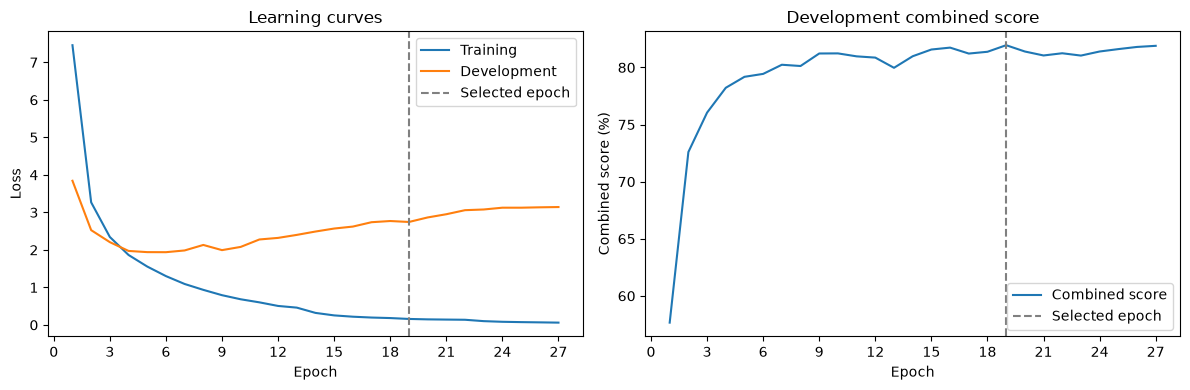

Epoch-level training evidence:
Epoch | Train loss | Dev loss | Intent accuracy (%) | Slot micro-F1 (%) | Combined (%) | Seconds
1 | 7.46 | 3.84 | 56.12 | 59.19 | 57.66 | 59.90
2 | 3.27 | 2.53 | 74.03 | 71.16 | 72.60 | 64.12
3 | 2.34 | 2.21 | 77.72 | 74.38 | 76.05 | 60.40
4 | 1.86 | 1.97 | 80.87 | 75.57 | 78.22 | 60.34
5 | 1.56 | 1.94 | 81.85 | 76.51 | 79.18 | 62.85
6 | 1.30 | 1.94 | 82.34 | 76.53 | 79.44 | 68.46
7 | 1.09 | 1.99 | 83.37 | 77.10 | 80.24 | 67.60
8 | 0.93 | 2.13 | 82.73 | 77.52 | 80.13 | 67.26
9 | 0.79 | 1.99 | 84.26 | 78.19 | 81.22 | 66.95
10 | 0.68 | 2.08 | 83.67 | 78.80 | 81.23 | 66.92
11 | 0.60 | 2.28 | 84.51 | 77.44 | 80.97 | 69.96
12 | 0.51 | 2.32 | 83.92 | 77.81 | 80.86 | 61.68
13 | 0.46 | 2.40 | 82.73 | 77.21 | 79.97 | 67.33
14 | 0.32 | 2.49 | 84.06 | 77.90 | 80.98 | 67.72
15 | 0.25 | 2.57 | 84.80 | 78.34 | 81.57 | 68.67
16 | 0.22 | 2.62 | 85.39 | 78.09 | 81.74 | 67.53
17 | 0.20 | 2.74 | 84.51 | 77.93 | 81.22 | 70.57
18 | 0.18 | 2.77 | 84.80 | 77.95 | 81.37 | 71.67

In [13]:
from matplotlib.ticker import MaxNLocator

history = stage1['history']
epochs = [row['epoch'] for row in history]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for key, label in [('train_loss', 'Training'), ('dev_loss', 'Development')]:
    axes[0].plot(epochs, [row[key] for row in history], label=label)
axes[0].set(xlabel='Epoch', ylabel='Loss', title='Learning curves')
axes[1].plot(epochs, [row['combined_score'] for row in history], label='Combined score')
axes[1].set(xlabel='Epoch', ylabel='Combined score (%)', title='Development combined score')
for axis in axes:
    axis.axvline(stage1['best_epoch'], color='gray', linestyle='--', label='Selected epoch')
    axis.xaxis.set_major_locator(MaxNLocator(integer=True))
    axis.legend()
fig.tight_layout()
plt.show()


print('Epoch-level training evidence:')
print('Epoch | Train loss | Dev loss | Intent accuracy (%) | Slot micro-F1 (%) | Combined (%) | Seconds')
for row in stage1['history']:
    print(f"{row['epoch']} | {row['train_loss']:.2f} | {row['dev_loss']:.2f} | "
          f"{row['intent_accuracy']:.2f} | {row['slot_micro_f1']:.2f} | "
          f"{row['combined_score']:.2f} | {row['elapsed_seconds']:.2f}")

## 9) Final evaluation on the baseline checkpoint

Reload the best saved checkpoint and evaluate the validation and test splits without further training. Verify that the validation score matches the selected checkpoint score, then report both task metrics to two decimal places.

In [14]:
def audit_metrics(model, loader, device, id2slot, expected):
    model.eval()
    num_intents = len(stage1['vocab'].intent2id)
    confusion = torch.zeros(num_intents, num_intents, dtype=torch.long)
    tp = fp = fn = 0
    with torch.no_grad():
        for batch in loader:
            mask = batch['attention_mask'].to(device)
            _, intent_logits, emissions = model(batch['input_ids'].to(device), mask,
                                                batch['seq_lens'].to(device))
            intents = intent_logits.argmax(-1).cpu()
            slots = model.decode_slots(emissions, mask).cpu()
            for i, length in enumerate(batch['seq_lens'].tolist()):
                confusion[int(batch['intent_label'][i]), int(intents[i])] += 1
                tokens = tokenize_words(batch['raw_utt'][i])
                gold = set(bio_tags_to_spans(tokens, _tags_from_ids(batch['slot_labels'][i, :length], id2slot)))
                pred = set(bio_tags_to_spans(tokens, _tags_from_ids(slots[i, :length], id2slot)))
                tp += len(gold & pred)
                fp += len(pred - gold)
                fn += len(gold - pred)
    accuracy = 100.0 * int(confusion.trace()) / int(confusion.sum())
    f1 = 100.0 * 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else 0.0
    assert int(confusion.sum()) == OFFICIAL_SPLITS['test']
    assert abs(accuracy - expected['intent_accuracy']) < 1e-9
    assert abs(f1 - expected['slot_micro_f1']) < 1e-9
    assert abs((accuracy + f1) / 2 - expected['combined_score']) < 1e-9
    return confusion, {'TP': tp, 'FP': fp, 'FN': fn}


checkpoint = torch.load(stage1['checkpoint_path'], map_location=stage1['device'])
stage1['model'].load_state_dict(checkpoint['model_state_dict'])
stage1['model'].eval()
validation_metrics = evaluate_model(stage1['model'], stage1['dataloaders']['dev'],
                                    stage1['device'], stage1['id2slot'], round_results=False)
assert abs(validation_metrics['combined_score'] - checkpoint['validation_score']) <= 1e-9
for key, value in stage1['best_dev_metrics'].items():
    assert abs(validation_metrics[key] - value) <= 1e-9, (key, value, validation_metrics[key])
test_metrics = evaluate_model(stage1['model'], stage1['dataloaders']['test'],
                             stage1['device'], stage1['id2slot'], round_results=False)

intent_confusion, slot_counts = audit_metrics(
    stage1['model'], stage1['dataloaders']['test'],
    stage1['device'], stage1['id2slot'], test_metrics)

print('FINAL EVALUATION')
print('-' * 66)
print(f"{'Split':<14}{'Intent accuracy':>18}{'Slot micro-F1':>18}{'Combined score':>16}")
print('-' * 66)
for split, metrics in [('Validation', validation_metrics), ('Test', test_metrics)]:
    accuracy_text = f"{metrics['intent_accuracy']:.2f}%"
    f1_text = f"{metrics['slot_micro_f1']:.2f}%"
    combined_text = f"{metrics['combined_score']:.2f}%"
    print(f"{split:<14}{accuracy_text:>18}{f1_text:>18}{combined_text:>16}")
print('-' * 66)
print('\nTest-set counts')
for label, value in [
    ('Correct intent predictions', int(intent_confusion.trace())),
    ('Total utterances', int(intent_confusion.sum())),
    ('Slot true positives (TP)', slot_counts['TP']),
    ('Slot false positives (FP)', slot_counts['FP']),
    ('Slot false negatives (FN)', slot_counts['FN']),
]:
    print(f'{label:<32}: {value:>8,}')


FINAL EVALUATION
------------------------------------------------------------------
Split            Intent accuracy     Slot micro-F1  Combined score
------------------------------------------------------------------
Validation                85.34%            78.56%          81.95%
Test                      83.42%            76.74%          80.08%
------------------------------------------------------------------

Test-set counts
Correct intent predictions      :    2,481
Total utterances                :    2,974
Slot true positives (TP)        :    2,178
Slot false positives (FP)       :      683
Slot false negatives (FN)       :      637
